# training -> sft, then two from scratch dpo runs (hh-rlhf and ultrafeedback)

## imports

In [1]:
#on kaggle, uncomment this so the alignment package next to this folder is importable
# !pip install -q -e .. --no-deps

In [2]:
from pathlib import Path
import json
import math
import os
import random
import time

DATA_DIR = Path('./data')
OUTPUT_DIR = Path('./outputs/train')
SUBSET_DIR = OUTPUT_DIR / 'subsets' #the exact train/val rows every run used
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
for directory in [DATA_DIR, OUTPUT_DIR, SUBSET_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

#set before the hugging face imports so the model and the datasets download into ./data, which is on the volume
#when this runs on modal -> a second run does not download anything again
os.environ['HF_HOME'] = str((DATA_DIR / 'hf').resolve())

import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import datasets
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

#the from scratch pieces. the grading adapter wraps these same functions, so what trains here is what gets graded
from alignment.batching import build_dpo_batch, build_lm_batch
from alignment.data import (format_prompt, hh_row, read_jsonl, select_examples, ultrachat_row, ultrafeedback_row,
                            write_jsonl)
from alignment.losses import dpo_forward, dpo_logits, dpo_loss_from_logps, sft_loss, token_logprobs

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## global env variables ->

In [3]:
#every value in this cell is the manual's guide configuration for kaggle t4 x2, so the notebook runs there unchanged.
#the modal runner's --scale flag overrides the batch layout and precision for a single 96gb card
SEED = 42
BASE_MODEL = 'Qwen/Qwen2.5-0.5B'

MAX_LENGTH = 512 #context length, prompt + response + eos
MAX_PROMPT_TOKENS = 256 #rows with a longer formatted prompt are dropped when the subsets are built

SFT_TRAIN_SIZE = 30000
DPO_TRAIN_SIZE = 15000 #per dpo run
VAL_SIZE = 1000 #per run

PRECISION = 'fp16' #autocast dtype -> 'fp16' (t4, needs gradient scaling), 'bf16' (newer cards) or 'fp32'
REFERENCE_HALF_PRECISION = True #the manual's t4 memory tip, the frozen reference's weights are stored in half precision

SFT_BATCH_SIZE = 2
SFT_GRAD_ACCUM = 16 #2 x 16 = effective batch 32
SFT_LEARNING_RATE = 2e-5
SFT_WARMUP_RATIO = 0.03
SFT_WEIGHT_DECAY = 0.1
SFT_EPOCHS = 1
SFT_EVAL_EVERY = 100 #optimizer steps between validation passes

DPO_BATCH_SIZE = 1 #pairs per forward pass
DPO_GRAD_ACCUM = 32 #1 x 32 = effective batch 32
DPO_LEARNING_RATE = 1e-6 #fixed, no warmup and no decay
DPO_BETA = 0.1
DPO_EPOCHS = 1
DPO_EVAL_EVERY = 50

GRADIENT_CLIP_NORM = 1.0
EVAL_BATCH_SIZE = 8
LOG_EVERY = 10 #optimizer steps between training log rows

In [4]:
# Parameters
SFT_BATCH_SIZE = 32
SFT_GRAD_ACCUM = 1
DPO_BATCH_SIZE = 16
DPO_GRAD_ACCUM = 2
EVAL_BATCH_SIZE = 32
PRECISION = "bf16"
REFERENCE_HALF_PRECISION = False


In [5]:
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
#on kaggle t4 x2 the frozen reference gets the second gpu to itself, on a single card it shares the first one
reference_device = torch.device('cuda:1') if torch.cuda.device_count() > 1 else device

#the manual's task 1 asks for the gpus and the package versions to be printed, this is that attestation
print(f'using device {device}  reference on {reference_device}')
for index in range(torch.cuda.device_count()):
    print(f'gpu {index} {torch.cuda.get_device_name(index)}  '
          f'memory {torch.cuda.get_device_properties(index).total_memory / 1024 ** 3:.0f} gb')
print(f'torch {torch.__version__}  cuda {torch.version.cuda}  '
      f'transformers {transformers.__version__}  datasets {datasets.__version__}')

AUTOCAST_DTYPE = {'fp16': torch.float16, 'bf16': torch.bfloat16}.get(PRECISION) #None means plain fp32


def autocast():
    #mixed precision for the forward pass only, the trainable weights themselves always stay fp32
    return torch.autocast(device_type=device.type, dtype=AUTOCAST_DTYPE,
                          enabled=device.type == 'cuda' and AUTOCAST_DTYPE is not None)


def make_scaler():
    #fp16 gradients underflow without loss scaling. bf16 has the exponent range of fp32, so it needs no scaler
    return torch.amp.GradScaler(device.type, enabled=device.type == 'cuda' and PRECISION == 'fp16')


def peak_memory_gb():
    return torch.cuda.max_memory_allocated(device) / 1024 ** 3 if device.type == 'cuda' else 0.0

using device cuda:0  reference on cuda:0
gpu 0 NVIDIA RTX PRO 6000 Blackwell Server Edition  memory 95 gb
torch 2.11.0+cu128  cuda 12.8  transformers 4.57.6  datasets 4.8.5


## data -> fixed single turn subsets

In [6]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
print(f'eos {tokenizer.eos_token!r} id {tokenizer.eos_token_id}  pad {tokenizer.pad_token!r} id {tokenizer.pad_token_id}')


def build_subset(name, dataset_name, split, convert, train_size):
    train_path = SUBSET_DIR / f'{name}_train.jsonl'
    val_path = SUBSET_DIR / f'{name}_val.jsonl'

    #reuse the saved subset when it has the requested sizes, so a restarted notebook trains on identical rows
    if train_path.exists() and val_path.exists():
        train_rows, val_rows = read_jsonl(train_path), read_jsonl(val_path)
        if len(train_rows) == train_size and len(val_rows) == VAL_SIZE:
            print(f'{name:4s} reused {len(train_rows)} train / {len(val_rows)} val from {SUBSET_DIR}')
            return train_rows, val_rows

    #seeded shuffle of the full split, then the first rows that are single turn, non empty and short enough
    dataset = load_dataset(dataset_name, split=split)
    examples = select_examples(dataset, convert, tokenizer, train_size + VAL_SIZE, SEED, MAX_PROMPT_TOKENS)
    assert len(examples) == train_size + VAL_SIZE, f'{name}: only {len(examples)} usable rows in {dataset_name}'

    #train and val are disjoint slices of the same shuffled selection
    train_rows, val_rows = examples[:train_size], examples[train_size:]
    write_jsonl(train_path, train_rows)
    write_jsonl(val_path, val_rows)
    print(f'{name:4s} built {len(train_rows)} train / {len(val_rows)} val from {len(dataset)} rows of {dataset_name}')
    return train_rows, val_rows


sft_train, sft_val = build_subset('sft', 'HuggingFaceH4/ultrachat_200k', 'train_sft', ultrachat_row, SFT_TRAIN_SIZE)
hh_train, hh_val = build_subset('hh', 'Anthropic/hh-rlhf', 'train', hh_row, DPO_TRAIN_SIZE)
uf_train, uf_val = build_subset('uf', 'HuggingFaceH4/ultrafeedback_binarized', 'train_prefs', ultrafeedback_row, DPO_TRAIN_SIZE)

eos '<|endoftext|>' id 151643  pad '<|endoftext|>' id 151643


Generating train_sft split:   0%|          | 0/207865 [00:00<?, ? examples/s]

Generating train_sft split:   4%|▍         | 8000/207865 [00:00<00:02, 71943.46 examples/s]

Generating train_sft split:   9%|▉         | 19000/207865 [00:00<00:02, 83421.63 examples/s]

Generating train_sft split:  14%|█▍        | 30000/207865 [00:00<00:01, 89728.53 examples/s]

...

Generating train_gen split:  79%|███████▊  | 48000/61135 [00:00<00:00, 153114.81 examples/s]

Generating train_gen split: 100%|██████████| 61135/61135 [00:00<00:00, 151284.24 examples/s]

Generating test_gen split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test_gen split: 100%|██████████| 1000/1000 [00:00<00:00, 39945.75 examples/s]

uf   built 15000 train / 1000 val from 61135 rows of HuggingFaceH4/ultrafeedback_binarized


In [7]:
#one formatted example per track, checked by eye before any gpu time is spent
print(format_prompt(sft_train[0]['instruction']) + sft_train[0]['response'][:300])
for name, pairs in [('hh', hh_train), ('uf', uf_train)]:
    print(f"\n--- {name} ---\n{format_prompt(pairs[0]['instruction'])}"
          f"[chosen] {pairs[0]['chosen'][:200]}\n[rejected] {pairs[0]['rejected'][:200]}")

### Instruction:
How does the location of the Sydney Conservatorium of Music impact the academic and professional opportunities available to music students, and how does the conservatorium support student engagement with the music industry in Australia?

### Response:
The location of the Sydney Conservatorium of Music, which is situated in the heart of Sydney's cultural precinct, impacts both the academic and professional opportunities available to music students. The conservatorium is located near several major performing arts venues and organizations, including

--- hh ---
### Instruction:
Why did cells originally combine together to create life?

### Response:
[chosen] Because their simple components -- chemicals -- interacted in particular ways.  And because of chemical processes involving acids and bases, certain kinds of chemicals can begin to self-organize into 
[rejected] Cells combine because they benefit from cooperation, since they can have less competition for resources by 

## loaders

In [8]:
def collate_sft(examples):
    #tokenized per batch and padded only to the longest row in it, with the prompt and padding labels set to -100
    prompts = [format_prompt(example['instruction']) for example in examples]
    responses = [example['response'] for example in examples]
    return build_lm_batch(tokenizer, prompts, responses, MAX_LENGTH)


def collate_dpo(examples):
    #the same formatted prompt goes in front of the chosen and the rejected response
    prompts = [format_prompt(example['instruction']) for example in examples]
    chosen = [example['chosen'] for example in examples]
    rejected = [example['rejected'] for example in examples]
    return build_dpo_batch(tokenizer, prompts, chosen, rejected, MAX_LENGTH)


def make_loader(rows, batch_size, collate, shuffle):
    #a seeded generator fixes the shuffle order, so two runs see the batches in the same order
    return DataLoader(rows, batch_size=batch_size, shuffle=shuffle, collate_fn=collate,
                      generator=torch.Generator().manual_seed(SEED) if shuffle else None)


def count_optimizer_steps(loader, grad_accum, epochs):
    #one optimizer step per grad_accum batches, the last group of an epoch may be smaller
    return math.ceil(len(loader) / grad_accum) * epochs


def save_checkpoint(model, name):
    #model and tokenizer together, so a checkpoint folder loads on its own in the generation notebook
    model.save_pretrained(CHECKPOINT_DIR / name)
    tokenizer.save_pretrained(CHECKPOINT_DIR / name)

## sft -> own training loop, loss on response tokens only

In [9]:
@torch.no_grad()
def evaluate_sft(model, loader):
    model.eval()
    logp_sum, token_count = 0.0, 0
    for batch in loader:
        with autocast():
            logps, mask = token_logprobs(model, batch) #both (n, t - 1)
        logp_sum += logps.sum().item()
        token_count += mask.sum().item()
    model.train()
    #same reduction as the training loss, the mean over every response token of the validation split
    return -logp_sum / max(token_count, 1)


def train_sft():
    run_name = 'sft'
    history_path = OUTPUT_DIR / f'{run_name}_history.csv'
    done_path = OUTPUT_DIR / f'{run_name}_done.json'
    if done_path.exists(): #a finished run is not repeated when the notebook is restarted
        print(f'{run_name} already finished, reusing {history_path}')
        return pd.read_csv(history_path)

    #trainable weights are loaded in fp32. autocast lowers the precision of the forward pass, not of the weights
    model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float32).to(device)
    model.train()

    train_loader = make_loader(sft_train, SFT_BATCH_SIZE, collate_sft, shuffle=True)
    val_loader = make_loader(sft_val, EVAL_BATCH_SIZE, collate_sft, shuffle=False)
    total_steps = count_optimizer_steps(train_loader, SFT_GRAD_ACCUM, SFT_EPOCHS)
    warmup_steps = int(total_steps * SFT_WARMUP_RATIO)

    optimizer = torch.optim.AdamW(model.parameters(), lr=SFT_LEARNING_RATE, weight_decay=SFT_WEIGHT_DECAY)

    def learning_rate_scale(step):
        if step < warmup_steps: #linear warmup from near 0 up to the peak rate
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps) #0 -> 1 over the rest of training
        return 0.5 * (1.0 + math.cos(math.pi * progress)) #cosine decay from the peak rate down to 0

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, learning_rate_scale)
    scaler = make_scaler()

    history = []
    best_val_loss = float('inf')
    best_step = 0
    step = 0
    window_losses = [] #batch losses since the last log row
    run_start = time.time()
    optimizer.zero_grad(set_to_none=True)

    for epoch in range(SFT_EPOCHS):
        for batch_index, batch in enumerate(train_loader, start=1):
            with autocast():
                loss = sft_loss(model, batch) #mean negative log probability over this batch's response tokens

            #divided by the accumulation count so the summed gradient is the average over the effective batch
            scaler.scale(loss / SFT_GRAD_ACCUM).backward()
            window_losses.append(loss.item())

            #keep accumulating until grad_accum batches are in, or the epoch runs out of batches
            if batch_index % SFT_GRAD_ACCUM != 0 and batch_index != len(train_loader):
                continue

            scaler.unscale_(optimizer) #back to true gradient magnitudes, otherwise the clip threshold is meaningless
            gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
            scaler.step(optimizer) #skips the update by itself if the fp16 gradients contain inf or nan
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            step += 1

            is_last_step = step == total_steps
            is_eval_step = step % SFT_EVAL_EVERY == 0 or is_last_step
            if step % LOG_EVERY == 0 or is_eval_step:
                row = {
                    'run': run_name,
                    'step': step,
                    'train_loss': sum(window_losses) / len(window_losses),
                    'val_loss': float('nan'), #filled in below on evaluation steps
                    'learning_rate': scheduler.get_last_lr()[0],
                    'gradient_norm': gradient_norm.item(), #the norm before clipping
                    'peak_memory_gb': peak_memory_gb(),
                    'seconds': time.time() - run_start,
                }
                window_losses.clear()

                if is_eval_step:
                    row['val_loss'] = evaluate_sft(model, val_loader)
                    if row['val_loss'] < best_val_loss: #best checkpoint = lowest validation loss
                        best_val_loss = row['val_loss']
                        best_step = step
                        save_checkpoint(model, 'sft_best')

                history.append(row)
                print(f"{run_name} step {step:4d}/{total_steps} | train {row['train_loss']:.4f} | "
                      f"val {row['val_loss']:.4f} | lr {row['learning_rate']:.2e} | "
                      f"grad {row['gradient_norm']:.2f} | mem {row['peak_memory_gb']:.1f} gb")
                if is_eval_step: #rewritten at every evaluation so partial progress survives a dropped run
                    pd.DataFrame(history).to_csv(history_path, index=False)

    save_checkpoint(model, 'sft_final')
    done_path.write_text(json.dumps({'run': run_name, 'steps': step, 'best_step': best_step,
                                     'best_val_loss': best_val_loss, 'seconds': time.time() - run_start}, indent=2))
    print(f'{run_name} done in {(time.time() - run_start) / 60:.1f} min, best val loss {best_val_loss:.4f} at step {best_step}')

    del model, optimizer #frees the gpu before the dpo runs load two more copies of the model
    torch.cuda.empty_cache()
    return pd.DataFrame(history)

In [10]:
sft_history = train_sft()

`torch_dtype` is deprecated! Use `dtype` instead!


sft step   10/938 | train 1.4106 | val nan | lr 7.86e-06 | grad 4.46 | mem 64.8 gb


sft step   20/938 | train 1.3813 | val nan | lr 1.50e-05 | grad 3.72 | mem 64.8 gb


sft step   30/938 | train 1.3975 | val nan | lr 2.00e-05 | grad 4.05 | mem 64.8 gb


sft step   40/938 | train 1.4672 | val nan | lr 2.00e-05 | grad 3.64 | mem 64.8 gb


...

sft step  910/938 | train 1.3872 | val nan | lr 4.67e-08 | grad 3.30 | mem 64.8 gb


sft step  920/938 | train 1.3768 | val nan | lr 1.93e-08 | grad 3.32 | mem 64.8 gb


sft step  930/938 | train 1.3598 | val nan | lr 3.81e-09 | grad 3.19 | mem 64.8 gb


sft step  938/938 | train 1.4314 | val 1.3490 | lr 0.00e+00 | grad 4.90 | mem 64.8 gb


sft done in 12.7 min, best val loss 1.3490 at step 938


## dpo -> own loss, trainable policy against a frozen copy of the sft checkpoint

In [11]:
@torch.no_grad()
def evaluate_dpo(policy, reference, loader):
    policy.eval()
    all_margins = []
    for batch in loader:
        with autocast():
            logps = dpo_forward(policy, reference, batch) #four (n,) tensors
        #beta * (policy gap - reference gap) is the reward margin r_w - r_l of each pair
        all_margins.append(dpo_logits(*logps, DPO_BETA).float().cpu())
    policy.train()

    margins = torch.cat(all_margins) #(number of validation pairs,)
    return {
        'val_loss': -F.logsigmoid(margins).mean().item(),
        #strict r_w > r_l -> exactly 0 while the policy still equals the reference, not 0.5
        'val_reward_accuracy': margins.gt(0).float().mean().item(),
        'val_reward_margin': margins.mean().item(),
    }


def train_dpo(run_name, train_pairs, val_pairs):
    history_path = OUTPUT_DIR / f'{run_name}_history.csv'
    done_path = OUTPUT_DIR / f'{run_name}_done.json'
    if done_path.exists():
        print(f'{run_name} already finished, reusing {history_path}')
        return pd.read_csv(history_path)

    sft_checkpoint = CHECKPOINT_DIR / 'sft_best' #both dpo runs start from this same checkpoint

    #the trainable policy, fp32 weights
    policy = AutoModelForCausalLM.from_pretrained(sft_checkpoint, torch_dtype=torch.float32).to(device)
    policy.train()

    #the frozen reference is a second copy of the same checkpoint. half precision weights are the manual's t4
    #memory tip, with fp32 the policy and the reference start out numerically identical
    use_half = REFERENCE_HALF_PRECISION and reference_device.type == 'cuda'
    reference = AutoModelForCausalLM.from_pretrained(sft_checkpoint, torch_dtype=torch.float16 if use_half else torch.float32)
    reference = reference.to(reference_device).eval()
    reference.requires_grad_(False) #belt and braces, its passes already run under no_grad

    train_loader = make_loader(train_pairs, DPO_BATCH_SIZE, collate_dpo, shuffle=True)
    val_loader = make_loader(val_pairs, EVAL_BATCH_SIZE, collate_dpo, shuffle=False)
    total_steps = count_optimizer_steps(train_loader, DPO_GRAD_ACCUM, DPO_EPOCHS)

    #small fixed learning rate and no weight decay -> the pull back toward the reference comes from the loss itself
    optimizer = torch.optim.AdamW(policy.parameters(), lr=DPO_LEARNING_RATE, weight_decay=0.0)
    scaler = make_scaler()

    #step 0 row, the starting point before any update
    history = [{'run': run_name, 'step': 0, **evaluate_dpo(policy, reference, val_loader)}]
    print(f"{run_name} step    0/{total_steps} | val loss {history[0]['val_loss']:.4f} | "
          f"val acc {history[0]['val_reward_accuracy']:.3f} | val margin {history[0]['val_reward_margin']:.4f}")

    best_accuracy = -1.0
    best_step = 0
    step = 0
    window_losses, window_margins = [], []
    run_start = time.time()
    optimizer.zero_grad(set_to_none=True)

    for epoch in range(DPO_EPOCHS):
        for batch_index, batch in enumerate(train_loader, start=1):
            with autocast():
                logps = dpo_forward(policy, reference, batch) #policy chosen/rejected, reference chosen/rejected
                loss = dpo_loss_from_logps(*logps, DPO_BETA)

            scaler.scale(loss / DPO_GRAD_ACCUM).backward() #gradients reach the policy only
            window_losses.append(loss.item())
            window_margins.append(dpo_logits(*logps, DPO_BETA).detach().float().cpu()) #for the train diagnostics

            if batch_index % DPO_GRAD_ACCUM != 0 and batch_index != len(train_loader):
                continue

            scaler.unscale_(optimizer)
            gradient_norm = torch.nn.utils.clip_grad_norm_(policy.parameters(), GRADIENT_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            step += 1

            is_last_step = step == total_steps
            is_eval_step = step % DPO_EVAL_EVERY == 0 or is_last_step
            if step % LOG_EVERY == 0 or is_eval_step:
                train_margins = torch.cat(window_margins)
                row = {
                    'run': run_name,
                    'step': step,
                    'train_loss': sum(window_losses) / len(window_losses),
                    'train_reward_accuracy': train_margins.gt(0).float().mean().item(),
                    'train_reward_margin': train_margins.mean().item(),
                    'gradient_norm': gradient_norm.item(),
                    'peak_memory_gb': peak_memory_gb(),
                    'seconds': time.time() - run_start,
                }
                window_losses.clear()
                window_margins.clear()

                if is_eval_step:
                    row.update(evaluate_dpo(policy, reference, val_loader))
                    if row['val_reward_accuracy'] > best_accuracy: #the manual's selection rule
                        best_accuracy = row['val_reward_accuracy']
                        best_step = step
                        save_checkpoint(policy, f'{run_name}_best')

                history.append(row)
                print(f"{run_name} step {step:4d}/{total_steps} | train {row['train_loss']:.4f} | "
                      f"train acc {row['train_reward_accuracy']:.3f} | val acc {row.get('val_reward_accuracy', float('nan')):.3f} | "
                      f"val margin {row.get('val_reward_margin', float('nan')):.4f} | mem {row['peak_memory_gb']:.1f} gb")
                if is_eval_step:
                    pd.DataFrame(history).to_csv(history_path, index=False)

    save_checkpoint(policy, f'{run_name}_final')
    done_path.write_text(json.dumps({'run': run_name, 'steps': step, 'best_step': best_step,
                                     'best_val_reward_accuracy': best_accuracy,
                                     'reference_checkpoint': str(sft_checkpoint),
                                     'seconds': time.time() - run_start}, indent=2))
    print(f'{run_name} done in {(time.time() - run_start) / 60:.1f} min, best val reward accuracy {best_accuracy:.3f} at step {best_step}')

    del policy, reference, optimizer
    torch.cuda.empty_cache()
    return pd.DataFrame(history)

## dpo run 1 : hh-rlhf, the safety oriented pairs

In [12]:
dpo_hh_history = train_dpo('dpo_hh', hh_train, hh_val)

dpo_hh step    0/469 | val loss 0.6931 | val acc 0.000 | val margin 0.0000


dpo_hh step   10/469 | train 0.6913 | train acc 0.463 | val acc nan | val margin nan | mem 64.8 gb


dpo_hh step   20/469 | train 0.6820 | train acc 0.566 | val acc nan | val margin nan | mem 64.8 gb


dpo_hh step   30/469 | train 0.6741 | train acc 0.562 | val acc nan | val margin nan | mem 64.8 gb


dpo_hh step   40/469 | train 0.6800 | train acc 0.562 | val acc nan | val margin nan | mem 64.8 gb


...

dpo_hh step  440/469 | train 0.6437 | train acc 0.637 | val acc nan | val margin nan | mem 64.8 gb


dpo_hh step  450/469 | train 0.6201 | train acc 0.616 | val acc 0.627 | val margin 0.1982 | mem 64.8 gb


dpo_hh step  460/469 | train 0.5971 | train acc 0.666 | val acc nan | val margin nan | mem 64.8 gb


dpo_hh step  469/469 | train 0.6293 | train acc 0.618 | val acc 0.633 | val margin 0.2167 | mem 64.8 gb


dpo_hh done in 24.8 min, best val reward accuracy 0.633 at step 469


## dpo run 2 : ultrafeedback, the general helpfulness pairs

In [13]:
dpo_uf_history = train_dpo('dpo_uf', uf_train, uf_val)

dpo_uf step    0/469 | val loss 0.6931 | val acc 0.000 | val margin 0.0000


dpo_uf step   10/469 | train 0.6749 | train acc 0.581 | val acc nan | val margin nan | mem 64.8 gb


dpo_uf step   20/469 | train 0.6493 | train acc 0.628 | val acc nan | val margin nan | mem 64.8 gb


dpo_uf step   30/469 | train 0.6463 | train acc 0.653 | val acc nan | val margin nan | mem 64.8 gb


dpo_uf step   40/469 | train 0.6452 | train acc 0.678 | val acc nan | val margin nan | mem 64.8 gb


...

dpo_uf step  440/469 | train 0.6099 | train acc 0.672 | val acc nan | val margin nan | mem 64.8 gb


dpo_uf step  450/469 | train 0.5994 | train acc 0.669 | val acc 0.709 | val margin 0.5915 | mem 64.8 gb


dpo_uf step  460/469 | train 0.5615 | train acc 0.712 | val acc nan | val margin nan | mem 64.8 gb


dpo_uf step  469/469 | train 0.5654 | train acc 0.718 | val acc 0.711 | val margin 0.5839 | mem 64.8 gb


dpo_uf done in 29.1 min, best val reward accuracy 0.711 at step 469


## the configuration actually used, and the training plots

In [14]:
#the report's configuration table must show the values the submitted checkpoints were trained with, not the guide's
run_config = {
    'base_model': BASE_MODEL, 'seed': SEED, 'max_length': MAX_LENGTH, 'max_prompt_tokens': MAX_PROMPT_TOKENS,
    'precision': PRECISION, 'reference_half_precision': REFERENCE_HALF_PRECISION,
    'gradient_clip_norm': GRADIENT_CLIP_NORM, 'prompt_template': format_prompt('{instruction}'),
    'gpus': [torch.cuda.get_device_name(index) for index in range(torch.cuda.device_count())],
    'sft': {'train_size': len(sft_train), 'val_size': len(sft_val), 'batch_size': SFT_BATCH_SIZE,
            'grad_accum': SFT_GRAD_ACCUM, 'effective_batch': SFT_BATCH_SIZE * SFT_GRAD_ACCUM,
            'optimizer': 'adamw', 'learning_rate': SFT_LEARNING_RATE, 'schedule': 'linear warmup + cosine decay',
            'warmup_ratio': SFT_WARMUP_RATIO, 'weight_decay': SFT_WEIGHT_DECAY, 'epochs': SFT_EPOCHS,
            'loss_reduction': 'mean over response tokens'},
    'dpo': {'train_size': DPO_TRAIN_SIZE, 'val_size': VAL_SIZE, 'batch_size': DPO_BATCH_SIZE,
            'grad_accum': DPO_GRAD_ACCUM, 'effective_batch': DPO_BATCH_SIZE * DPO_GRAD_ACCUM,
            'optimizer': 'adamw', 'learning_rate': DPO_LEARNING_RATE, 'schedule': 'constant', 'weight_decay': 0.0,
            'beta': DPO_BETA, 'epochs': DPO_EPOCHS, 'reference': 'frozen sft_best', 'selection': 'val reward accuracy'},
}
(OUTPUT_DIR / 'run_config.json').write_text(json.dumps(run_config, indent=2))
print(json.dumps(run_config, indent=2))

{
  "base_model": "Qwen/Qwen2.5-0.5B",
  "seed": 42,
  "max_length": 512,
  "max_prompt_tokens": 256,
  "precision": "bf16",
  "reference_half_precision": false,
  "gradient_clip_norm": 1.0,
  "prompt_template": "### Instruction:\n{instruction}\n\n### Response:\n",
  "gpus": [
    "NVIDIA RTX PRO 6000 Blackwell Server Edition"
  ],
  "sft": {
    "train_size": 30000,
    "val_size": 1000,
    "batch_size": 32,
    "grad_accum": 1,
    "effective_batch": 32,
    "optimizer": "adamw",
    "learning_rate": 2e-05,
    "schedule": "linear warmup + cosine decay",
    "warmup_ratio": 0.03,
    "weight_decay": 0.1,
    "epochs": 1,
    "loss_reduction": "mean over response tokens"
  },
  "dpo": {
    "train_size": 15000,
    "val_size": 1000,
    "batch_size": 16,
    "grad_accum": 2,
    "effective_batch": 32,
    "optimizer": "adamw",
    "learning_rate": 1e-06,
    "schedule": "constant",
    "weight_decay": 0.0,
    "beta": 0.1,
    "epochs": 1,
    "reference": "frozen sft_best",
    "sel

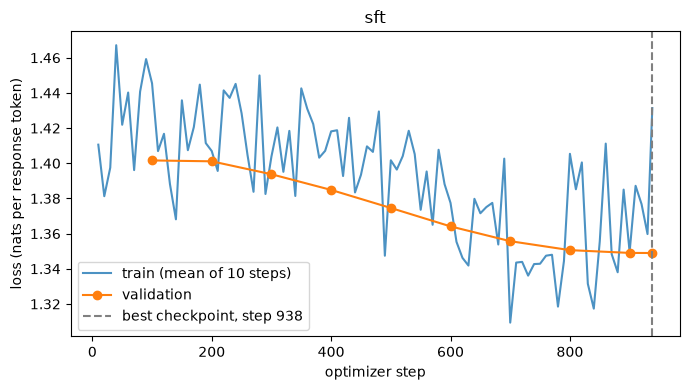

In [15]:
#sft -> training loss per log row (already a mean over LOG_EVERY steps, no extra smoothing) and validation loss
figure, axis = plt.subplots(figsize=(7, 4))
sft_val_rows = sft_history.dropna(subset=['val_loss'])
axis.plot(sft_history['step'], sft_history['train_loss'], label=f'train (mean of {LOG_EVERY} steps)', alpha=0.8)
axis.plot(sft_val_rows['step'], sft_val_rows['val_loss'], marker='o', label='validation')
best_row = sft_val_rows.loc[sft_val_rows['val_loss'].idxmin()]
axis.axvline(best_row['step'], color='gray', linestyle='--', label=f"best checkpoint, step {int(best_row['step'])}")
axis.set_xlabel('optimizer step')
axis.set_ylabel('loss (nats per response token)')
axis.set_title('sft')
axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT_DIR / 'sft_loss.png', dpi=150)
plt.show()

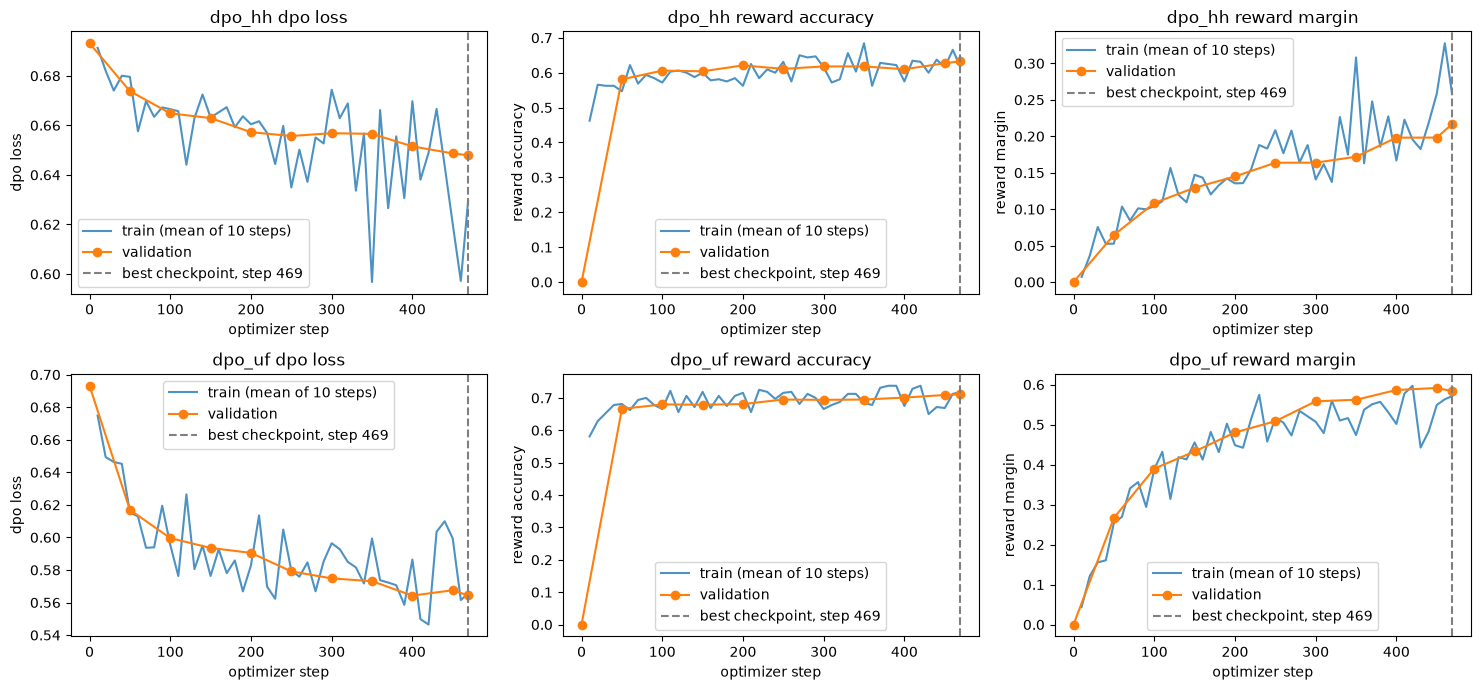

In [16]:
#dpo -> loss, reward accuracy and reward margin for both runs, validation as markers over the training curve
figure, axes = plt.subplots(2, 3, figsize=(15, 7))
for row_axes, (run_name, history) in zip(axes, [('dpo_hh', dpo_hh_history), ('dpo_uf', dpo_uf_history)]):
    train_rows = history.dropna(subset=['train_loss'])
    val_rows = history.dropna(subset=['val_loss'])
    best_row = val_rows.loc[val_rows[val_rows['step'] > 0]['val_reward_accuracy'].idxmax()] #step 0 is never saved
    for axis, metric, label in zip(row_axes, ['loss', 'reward_accuracy', 'reward_margin'],
                                   ['dpo loss', 'reward accuracy', 'reward margin']):
        axis.plot(train_rows['step'], train_rows[f'train_{metric}'], label=f'train (mean of {LOG_EVERY} steps)', alpha=0.8)
        axis.plot(val_rows['step'], val_rows[f'val_{metric}'], marker='o', label='validation')
        axis.axvline(best_row['step'], color='gray', linestyle='--', label=f"best checkpoint, step {int(best_row['step'])}")
        axis.set_xlabel('optimizer step')
        axis.set_ylabel(label)
        axis.set_title(f'{run_name} {label}')
        axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT_DIR / 'dpo_training.png', dpi=150)
plt.show()